# Senior results

What RL adds on top of imitation, and what imitation adds to RL, on IEEE-36 (`l2rpn_wcci_2020`). Four
agents share one network: the Junior's architecture and observation space (CompleteGraphObsSpace, no
forecasts), with dropout 0 in RL.

- **junior**: the pretrained policy (best trial of `junior2_hard`), no RL.
- **senior (warm-up)**: PPO from the Junior's weights. For the first `imitation.critic_warmup_iters`
  iterations only the value branch trains; the actor and the GNN are frozen.
- **senior (no warm-up)**: PPO from the Junior's weights, actor and critic trained from the start.
- **baseline**: PPO from random weights.

Each RL agent runs with several seeds (`slurm/unicluster/imitation_vs_rl36.sh`), the junior once (its
rollouts are deterministic). Sections: training curves (A), the critic warm-up (B) and survival on the
val and test envs (C).

**Splits.** RL trains on `l2rpn_wcci_2020_train` and evaluates greedily on `l2rpn_wcci_2020_val` during
training (section A). Section C rolls every agent out on both `l2rpn_wcci_2020_val` and
`l2rpn_wcci_2020_test` (144 chronics each). Val is comparable with the Junior survival tables
(`experiments/junior_results.ipynb`), but the Junior to start from was picked by its val survival, so
val is slightly optimistic for it. No stage has seen test.

**Data.** `EXPERIMENT` in the next cell selects `results/senior/<EXPERIMENT>/`; figures go to
`experiments/figures/senior_results/<EXPERIMENT>/`. A local copy needs one rsync (no checkpoints or
weights):

```
results/senior/<experiment>/<agent>_s<seed>/   .hydra/config.yaml, CustomPPO_*/events.out.tfevents.*
results/senior/<experiment>/eval/<agent>/      rollout[_top<k>]/episodes_{valenv,testenv}_*.csv
results/senior/<experiment>/eval/{tutor,do_nothing}/rollout/   reference rollouts

rsync -avm --include '*/' --include 'config.yaml' --include 'events.out.tfevents.*' \
    --include 'episodes_*.csv' --exclude '*' \
    <cluster>:<repo>/results/senior/<experiment>/ results/senior/<experiment>/
```

In [1]:
import sys
import warnings
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from matplotlib.lines import Line2D

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from analysis.episodes import load_episodes, survival_metrics
from analysis.training_curves import SENIOR_TAGS, load_scalars

# ── Experiment ──
EXPERIMENT = "2026_10_24_IEEE36_senior_pilot"  # results/senior/<EXPERIMENT>/, the name given to imitation_vs_rl36.sh
RL_AGENTS = {                            # label -> run name prefix (runs are <prefix>_s<seed>)
    "senior (warm-up)": "senior_warmup",
    "senior (no warm-up)": "senior_nowarmup",
    "baseline": "baseline",
}
JUNIOR = "junior"

# ── Paths ──
EXP_DIR = ROOT / "results/senior" / EXPERIMENT
assert EXP_DIR.exists(), f"{EXP_DIR} not found: copy it from the cluster (rsync command above)"
EVAL_DIR = EXP_DIR / "eval"  # eval/<agent>[_s<seed>]/rollout*/, eval/tutor/, eval/do_nothing/
FIGURES = ROOT / "experiments/figures/senior_results" / EXPERIMENT
FIGURES.mkdir(parents=True, exist_ok=True)

# ── Constants ──
K_MARKS = (1, 5, 20, 50)  # k of the top-k simulation rollouts
ROLLOUT_MODES = {"argmax": "rollout", **{f"top-{k}": f"rollout_top{k}" for k in K_MARKS}}  # mode -> folder
SPLITS = {"val": "valenv", "test": "testenv"}  # Grid2Op env -> tag of the episode files
WARMUP_ZOOM = 3  # section B shows the first WARMUP_ZOOM x warm-up iterations

# ── Palette: one fixed categorical slot per agent, references in neutral ink ──
AGENT_COLORS = {JUNIOR: "#2a78d6", "senior (warm-up)": "#eb6834", "senior (no warm-up)": "#1baf7a",
                "baseline": "#eda100"}
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"


def style(ax: plt.Axes) -> None:
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK_MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def agent_handles(agents: list[str], *extra: Line2D) -> list[Line2D]:
    """Legend entries: one line per agent, then `extra` (line styles in neutral ink)."""
    return [Line2D([0], [0], color=AGENT_COLORS[a], linewidth=2, label=a) for a in agents] + list(extra)


def finish(fig: plt.Figure, title: str, handles: list[Line2D], name: str) -> None:
    """Legend, title, layout; saves to experiments/figures/senior_results/<EXPERIMENT>/<name>.png."""
    fig.legend(handles=handles, frameon=False, ncols=len(handles), loc="upper right", labelcolor=INK, fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", color=INK, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.55 / fig.get_figheight()))
    fig.savefig(FIGURES / f"{name}.png", dpi=150, facecolor=SURFACE, bbox_inches="tight")
    plt.show()

In [2]:
def run_dirs(prefix: str) -> dict[int, Path]:
    """seed -> train.py output directory (<prefix>_s<seed>) of one RL agent, for the runs that exist."""
    runs = {}
    for d in sorted(EXP_DIR.glob(f"{prefix}_s*")):
        seed = d.name.removeprefix(f"{prefix}_s")
        if d.is_dir() and seed.isdigit():
            runs[int(seed)] = d
    return runs


def trial_dir(run: Path) -> Path:
    """The run's Tune trial directory (the newest, if Tune restarted the trial)."""
    return sorted(event.parent for event in run.glob("*/events.out.tfevents.*"))[-1]


RUNS = {label: runs for label, prefix in RL_AGENTS.items() if (runs := run_dirs(prefix))}
assert RUNS, f"No RL runs in {EXP_DIR}"
CONFIGS = {(label, seed): yaml.safe_load((run / ".hydra/config.yaml").read_text())
           for label, runs in RUNS.items() for seed, run in runs.items()}
CURVES = {(label, seed): load_scalars(trial_dir(run), SENIOR_TAGS)
          for label, runs in RUNS.items() for seed, run in runs.items()}

pd.DataFrame({
    key: {"iterations": len(curve), "agent steps": int(curve["timesteps"].iloc[-1]),
          "warm-up iterations": CONFIGS[key]["imitation"]["critic_warmup_iters"]
          if CONFIGS[key]["imitation"].get("weights_path") else 0}
    for key, curve in CURVES.items()
}).T.rename_axis(["agent", "seed"])

,,iterations,agent steps,warm-up iterations
agent,seed,,,
senior (warm-up),0,27,30904,10
senior (no warm-up),0,27,31049,0
baseline,0,26,30971,0


# A. Training curves

Left: survival in the training episodes, where actions are sampled from the policy (mean last
grid2op step of the episodes that ended in an iteration). Right: survival on the val env with greedy
(argmax) actions, evaluated every `evaluation.evaluation_interval` iterations. Lines: mean over
seeds; bands: min to max over seeds (curves interpolated onto a common step grid). Dashed: mean steps
survived by the junior's greedy val rollout, the RL agents' starting point. RLlib's evaluation draws its
own seeds, so that line is an approximate reference.

Neither curve uses top-k simulation, so both lie well below the survival in section C.

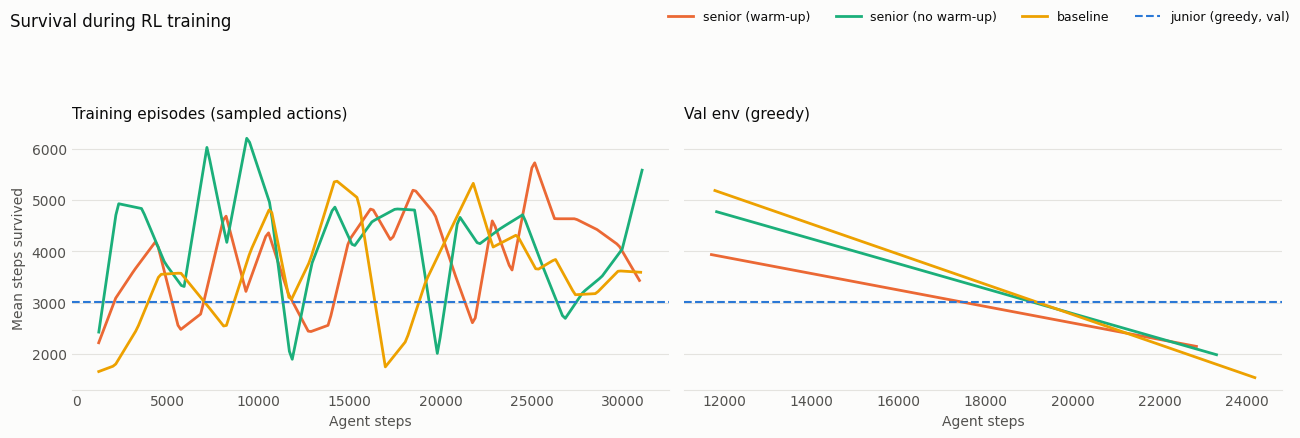

In [3]:
def eval_rows(curve: pd.DataFrame, config: dict) -> pd.DataFrame:
    """Iterations in which evaluation ran; RLlib repeats the last evaluation results in between."""
    return curve[curve["iteration"] % config["evaluation"]["evaluation_interval"] == 0]


def seed_band(curves: list[pd.DataFrame], column: str, grid: np.ndarray) -> tuple[np.ndarray, ...]:
    """Mean, min and max over seeds of `column`, interpolated onto `grid` (agent steps); NaN outside a run."""
    values = []
    for curve in curves:
        curve = curve.dropna(subset=[column])
        values.append(np.interp(grid, curve["timesteps"], curve[column], left=np.nan, right=np.nan))
    values = np.array(values)
    with warnings.catch_warnings():  # grid points past the end of every run are all-NaN
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmean(values, axis=0), np.nanmin(values, axis=0), np.nanmax(values, axis=0)


def junior_steps_survived(tag: str) -> float:
    """Mean steps survived by the junior's greedy rollout on one env split; NaN if not there."""
    files = sorted((EVAL_DIR / JUNIOR / "rollout").glob(f"episodes_{tag}_*.csv"))
    return load_episodes(*files)["steps_survived"].mean() if files else np.nan


panels = [("train_survival", "Training episodes (sampled actions)", lambda c, cfg: c),
          ("eval_survival", "Val env (greedy)", eval_rows)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), facecolor=SURFACE, sharey=True)
for ax, (column, title, select) in zip(axes, panels):
    for label, runs in RUNS.items():
        curves = [select(CURVES[(label, s)], CONFIGS[(label, s)]) for s in runs]
        grid = np.linspace(0, max(c["timesteps"].max() for c in curves), 200)
        mean, low, high = seed_band(curves, column, grid)
        ax.fill_between(grid, low, high, color=AGENT_COLORS[label], alpha=0.15, linewidth=0)
        ax.plot(grid, mean, color=AGENT_COLORS[label], linewidth=2)
    ax.axhline(junior_steps_survived(SPLITS["val"]), color=AGENT_COLORS[JUNIOR], linewidth=1.5, linestyle="--")
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xlabel("Agent steps", color=INK_MUTED)
    style(ax)
axes[0].set_ylabel("Mean steps survived", color=INK_MUTED)
junior_handle = Line2D([0], [0], color=AGENT_COLORS[JUNIOR], linewidth=1.5, linestyle="--", label="junior (greedy, val)")
finish(fig, "Survival during RL training", agent_handles(list(RUNS), junior_handle), "training_curves")

# B. Critic warm-up

During the warm-up the actor and the GNN are frozen, so the policy that collects the data stays the
Junior's: the KL between the sampling policy and the updated one should be 0 (exactly 0 with dropout 0,
since frozen BatchNorm layers stay in eval mode), and the policy loss carries no gradient. Only the
value branch learns, so the value loss should fall and the explained variance rise until the warm-up
ends (vertical line). The runs without warm-up and the baseline are shown over the same iterations for
comparison. Thin lines: one per seed.

RLlib's `vf_loss` is the clipped squared error, min((V − target)², `training.vf_clip_param`) per sample.
A sample whose error is beyond the clip gives no gradient, so a value loss stuck near the clip value
means the critic can't learn from most samples. That was the case in all earlier PPO runs: the RL agent
collects the reward of every grid step until its next decision, so its value targets were hundreds of
steps. These runs normalize the reward by the episode length (`reward.normalize_by_episode_length`): the
value target is the share of the chronic still to survive, in [0, 1], and the clip never triggers.

After the warm-up the KL is no longer exactly 0 even before the actor has changed much: in updates
RLlib runs the GNN in train mode, where BatchNorm normalizes with the batch's statistics, while sampling
uses the running statistics. That mismatch exists in every run with this GNN; it shrinks as the running
statistics adapt to the RL data.

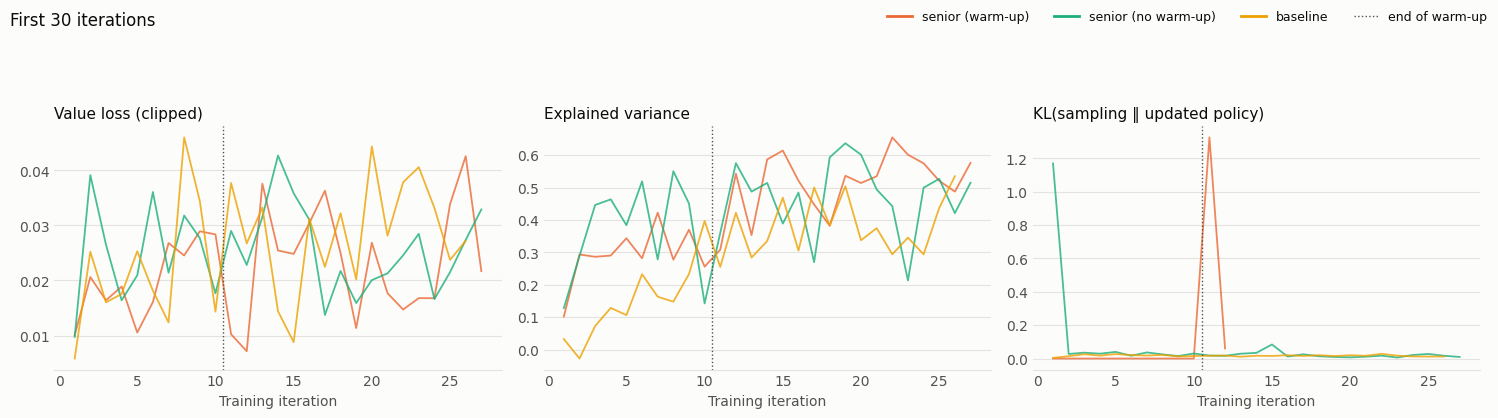

In [4]:
WARMUP_PANELS = {"vf_loss": "Value loss (clipped)", "vf_explained_var": "Explained variance",
                 "kl": "KL(sampling ‖ updated policy)"}
warmup_iters = max(CONFIGS[key]["imitation"]["critic_warmup_iters"] for key in CONFIGS
                   if CONFIGS[key]["imitation"].get("weights_path"))
zoom = max(WARMUP_ZOOM * warmup_iters, 10)

fig, axes = plt.subplots(1, len(WARMUP_PANELS), figsize=(15, 4.2), facecolor=SURFACE, sharex=True)
for ax, (column, title) in zip(axes, WARMUP_PANELS.items()):
    for (label, seed), curve in CURVES.items():
        head = curve[curve["iteration"] <= zoom]
        ax.plot(head["iteration"], head[column], color=AGENT_COLORS[label], linewidth=1.3, alpha=0.8)
    ax.axvline(warmup_iters + 0.5, color=INK_MUTED, linewidth=1, linestyle=":")
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xlabel("Training iteration", color=INK_MUTED)
    style(ax)
warmup_handle = Line2D([0], [0], color=INK_MUTED, linewidth=1, linestyle=":", label="end of warm-up")
finish(fig, f"First {zoom} iterations", agent_handles(list(RUNS), warmup_handle), "critic_warmup")

In [5]:
# Warm-up iterations of the senior (warm-up) runs: mean over seeds, then the first iterations after it.
warmup_curves = pd.concat([CURVES[("senior (warm-up)", s)] for s in RUNS["senior (warm-up)"]])
(warmup_curves[warmup_curves["iteration"] <= warmup_iters + 5]
 .groupby("iteration")[list(WARMUP_PANELS) + ["policy_loss"]].mean().round(4))

,vf_loss,vf_explained_var,kl,policy_loss
iteration,,,,
1,0.0101,0.1021,-0.0000,-0.0043
2,0.0206,0.2935,0.0000,0.0198
3,0.0164,0.2863,-0.0000,0.0359
4,0.0189,0.2902,0.0000,0.0012
5,0.0105,0.3435,0.0000,-0.0003
6,0.0161,0.2818,0.0000,0.0024
7,0.0268,0.4226,-0.0000,-0.0002
8,0.0245,0.2776,-0.0000,0.0008
9,0.0289,0.3698,-0.0000,0.0007


# C. Survival on the val and test envs

Rollouts of the final policies on all 144 chronics of each env (`experiments/imitation_rollout.py`).
Every policy plays the same chronics with the same seeds. While max rho stays at or below 0.95 every
agent plays do-nothing, and disconnected lines are reconnected by a fixed rule. Above 0.95 the agent
decides:

- **argmax**: the network's most probable action.
- **top-k**: the network's k most probable actions and do-nothing are simulated, and the Tutor's rule
  picks among them (the best one, if it beats do-nothing by more than the Tutor's margin).
- **Tutor** (all actions): top-k with every action, i.e. the Tutor itself.
- **Do-nothing**: always do-nothing.

The RL agents' metrics are means over seeds; **SD** is the standard deviation over seeds (– for a single
policy). Within one policy, the binomial standard error of full survival on 144 chronics is about ±3–4
points, so smaller differences are noise. Per-day rates are per day survived (288 steps), as in the
Junior tables. Missing rollouts show as –.

In [6]:
def rollout_folders() -> dict[tuple[str, str], list[Path]]:
    """(agent, mode) -> one rollout folder per seed (one for the junior and the references)."""
    folders = {(JUNIOR, mode): [EVAL_DIR / JUNIOR / folder] for mode, folder in ROLLOUT_MODES.items()}
    for label, prefix in RL_AGENTS.items():
        for mode, folder in ROLLOUT_MODES.items():
            folders[(label, mode)] = [EVAL_DIR / f"{prefix}_s{seed}" / folder for seed in RUNS.get(label, {})]
    folders[("Tutor", "all actions")] = [EVAL_DIR / "tutor/rollout"]
    folders[("Do-nothing", "–")] = [EVAL_DIR / "do_nothing/rollout"]
    return folders


def seed_metrics(folders: list[Path], tag: str) -> pd.DataFrame:
    """`SurvivalMetrics` of each folder with episode tables of one env split, one row per seed."""
    rows = [asdict(survival_metrics(load_episodes(*files)))
            for folder in folders if (files := sorted(folder.glob(f"episodes_{tag}_*.csv")))]
    return pd.DataFrame(rows)


def survival_row(metrics: pd.DataFrame) -> dict[str, float]:
    """One table row: means over seeds, and the SD over seeds of both survival measures."""
    if metrics.empty:
        return {}
    return {
        "seeds": len(metrics),
        "chronics": metrics["chronics"].min(),
        "full survival %": metrics["full_survival_pct"].mean(),
        "full SD": metrics["full_survival_pct"].std(),
        "mean survival %": metrics["mean_survival_pct"].mean(),
        "mean SD": metrics["mean_survival_pct"].std(),
        "decisions / day": metrics["decisions_per_day"].mean(),
        "actions / day": metrics["actions_per_day"].mean(),
        "illegal / day": metrics["illegal_per_day"].mean(),
    }


SURVIVAL = {}
for split, tag in SPLITS.items():
    table = pd.DataFrame.from_dict({key: survival_row(seed_metrics(folders, tag))
                                    for key, folders in rollout_folders().items()}, orient="index")
    table.index = pd.MultiIndex.from_tuples(table.index, names=["agent", "mode"])
    SURVIVAL[split] = table
    print(f"{split} env")
    display(table.style.format({"seeds": "{:.0f}", "chronics": "{:.0f}", "decisions / day": "{:.2f}",
                                "actions / day": "{:.2f}", "illegal / day": "{:.2f}"}, precision=1, na_rep="–"))

val env


test env


agent,mode


## Full survival per mode

Full survival per agent and mode on both envs. Points: mean over seeds; bars: min to max over seeds.
Horizontal lines: the Tutor (solid) and do-nothing (dashed).

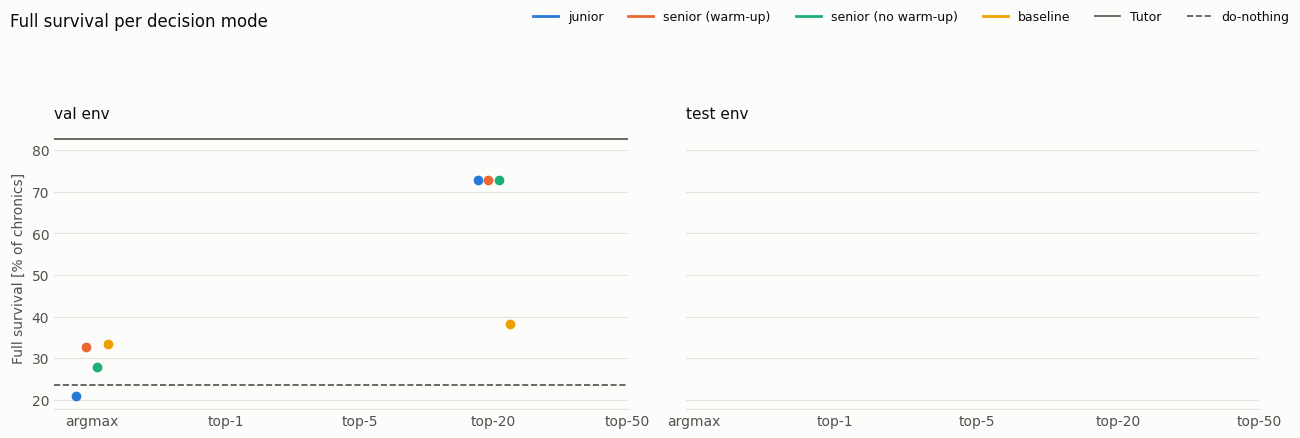

In [7]:
def survival_spread(folders: list[Path], tag: str) -> tuple[float, float, float]:
    """Mean, min and max over seeds of full survival in %; NaN if no rollout."""
    values = seed_metrics(folders, tag).get("full_survival_pct", pd.Series(dtype=float))
    return (values.mean(), values.min(), values.max()) if len(values) else (np.nan,) * 3


modes = list(ROLLOUT_MODES)
agents = [JUNIOR, *RUNS]
folders = rollout_folders()
x = np.arange(len(modes))
fig, axes = plt.subplots(1, len(SPLITS), figsize=(13, 4.4), facecolor=SURFACE, sharey=True)
for ax, (split, tag) in zip(axes, SPLITS.items()):
    for i, agent in enumerate(agents):
        spread = np.array([survival_spread(folders[(agent, mode)], tag) for mode in modes])
        offset = (i - (len(agents) - 1) / 2) * 0.08
        ax.errorbar(x + offset, spread[:, 0], yerr=[spread[:, 0] - spread[:, 1], spread[:, 2] - spread[:, 0]],
                    color=AGENT_COLORS[agent], marker="o", linewidth=2, capsize=3)
    ax.axhline(survival_spread(folders[("Tutor", "all actions")], tag)[0], color=INK_MUTED, linewidth=1.2)
    ax.axhline(survival_spread(folders[("Do-nothing", "–")], tag)[0], color=INK_MUTED, linewidth=1.2, linestyle="--")
    ax.set_xticks(x, modes)
    ax.set_title(f"{split} env", loc="left", color=INK, fontsize=11)
    style(ax)
axes[0].set_ylabel("Full survival [% of chronics]", color=INK_MUTED)
references = [Line2D([0], [0], color=INK_MUTED, linewidth=1.2, label="Tutor"),
              Line2D([0], [0], color=INK_MUTED, linewidth=1.2, linestyle="--", label="do-nothing")]
finish(fig, "Full survival per decision mode", agent_handles(agents, *references), "survival_per_mode")